# 05a — Silver RENAMU: selección de variables

**Objetivo del proyecto:** la toma de decisiones sobre el presupuesto y la ejecución de **ingresos** municipales.
El SIAF es la fuente principal. Del RENAMU nos quedamos solo con lo más importante y comparable entre años.

| Parte | Qué muestra |
| --- | --- |
| 1 | Estructura de los diccionarios 2020–2026: módulos y secciones |
| 2 | Secciones con 2 preguntas de ejemplo |
| 3 | Tamaño de cada edición y **la elección**: variables globales + *Finanzas municipales* |
| 4 | Códigos elegidos en 2020–2026: ¿están en el CSV de cada edición? |
| 5 | Los mismos códigos en 2009–2019 |
| 6 | Resultado: total de ingresos declarados por año |

Los códigos quedan en `data/silver/renamu_mapeo.yaml`, que también usa `05b`. La interpretación está en `data/silver/silver.md`, sección 05a.

## 0. Configuración

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ARQUITECTURA.md").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import cargar_config
from src.spark import crear_sesion
from src import bronze
from src.perfilado import detectar_formato, leer_csv, a_pandas
from src.renamu import extraer_diccionario, estructura_diccionario, cargar_mapeo

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
cfg = cargar_config()
A0, A1 = cfg["anios"]["renamu_analisis"]
spark = crear_sesion("silver_renamu_mapeo")

man = pd.DataFrame(bronze.leer_manifest()["archivos"])
f3 = man[(man["fuente"] == "F3") & (man["origen"] == "extraido_de_zip")].copy()
f3 = f3[~f3["ruta"].str.contains("_F02_")]   # F02 = centros poblados: fuera de alcance
f3["anio"] = f3["anio"].astype(int)
f3["ext"] = f3["archivo"].str.rsplit(".", n=1).str[-1].str.lower()
csvs = f3[(f3["ext"] == "csv") & (f3["archivo"] != "CDIR.csv")]      # CDIR = directorio con datos de contacto: no se usa

def pdfs(anio):
    return [RAIZ / p for p in f3[(f3["anio"] == anio) & (f3["ext"] == "pdf")]["ruta"]]

def a_numero(s):
    """Montos del RENAMU: coma decimal en casi todas las ediciones, punto en 2023–2024, sin separador de miles."""
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", ".", regex=False), errors="coerce")

print("Ediciones de análisis:", A0, "–", A1)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/22 14:22:26 WARN Utils: Your hostname, Rodrigo, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/22 14:22:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/22 14:22:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Ediciones de análisis: 2020 – 2026


## 1. Estructura de los diccionarios 2020–2026

Cada diccionario se organiza en `DEFINICIÓN DE VARIABLES GLOBALES`, `MÓDULO I … V` y, dentro de los módulos IV y V, **secciones** con título en mayúsculas.
Se lee el texto del PDF en orden y cada campo queda en el último título visto. La tabla cuenta los campos de cada sección por edición.

> Un 0 no siempre significa que la sección falte. Por ejemplo, el PDF de 2021 no titula "Gestión de administración tributaria", así que sus campos se cuentan en la sección anterior.

In [2]:
est = pd.concat([estructura_diccionario(pdfs(a)).assign(edicion=a) for a in range(A0, A1 + 1)], ignore_index=True)
modulo = est[est["edicion"] == A1].groupby("seccion_canonica")["modulo"].first().str.extract(r"(M[ÓO]DULO\s+[IVX]+)")[0]
orden = est[est["edicion"] == A1].drop_duplicates("seccion_canonica")["seccion_canonica"].tolist()
matriz = est.pivot_table(index="seccion_canonica", columns="edicion", values="campo", aggfunc="count", fill_value=0)
matriz.insert(0, "módulo", modulo)
display(matriz.loc[orden + [s for s in matriz.index if s not in orden]])

edicion,módulo,2020,2021,2022,2023,2024,2025,2026
seccion_canonica,,,,,,,,
DATOS GENERALES DE LA MUNICIPALIDAD,MÓDULO I,20,19,19,21,21,21,21
EQUIPAMIENTO Y TECNOLOGÍAS DE LA INFORMACIÓN Y COMUNICACIONES,MÓDULO II,91,95,95,96,96,100,100
RECURSOS HUMANOS,MÓDULO III,116,123,122,102,103,125,126
PLANIFICACIÓN MUNICIPAL,MÓDULO IV,92,106,91,91,93,100,97
GESTIÓN DE ADMINISTRACIÓN TRIBUTARIA,MÓDULO IV,12,0,10,9,9,10,10
LICENCIAS OTORGADAS POR LA MUNICIPALIDAD,MÓDULO IV,5,0,5,15,14,5,6
DESARROLLO URBANO Y/O RURAL,MÓDULO IV,39,31,31,28,28,32,32
SANEAMIENTO AMBIENTAL Y SALUBRIDAD,MÓDULO V,58,61,61,51,53,61,68
"EDUCACIÓN, CULTURA, DEPORTE Y RECREACIÓN",MÓDULO V,76,24,77,72,70,81,81


## 2. Secciones y 2 preguntas de ejemplo (edición 2026)

In [3]:
cat = pd.concat([extraer_diccionario(p) for p in pdfs(A1)], ignore_index=True)
cat["campo_u"] = cat["campo"].str.upper()
e = est[est["edicion"] == A1].merge(cat[["campo_u", "pregunta"]], left_on="campo", right_on="campo_u", how="left")

def ejemplos(g, n=2):
    out = []
    for q, h in g[~g["campo"].str.startswith("VFI")].groupby("nro_pregunta", sort=False):
        t = next((x for x in h["pregunta"] if isinstance(x, str) and x), h["texto"].iloc[0])
        out.append(f"{q}: {t[:65]}")
        if len(out) == n:
            break
    return " · ".join(out)

secciones = pd.DataFrame([{"módulo": "—", "sección": "DEFINICIÓN DE VARIABLES GLOBALES", "preguntas de ejemplo": "Ubigeo · Tipomuni (provincial / distrital)"}] +
                         [{"módulo": modulo.get(s), "sección": s, "preguntas de ejemplo": ejemplos(e[e["seccion_canonica"] == s])} for s in orden])
display(secciones)

,módulo,sección,preguntas de ejemplo
0,—,DEFINICIÓN DE VARIABLES GLOBALES,Ubigeo · Tipomuni (provincial / distrital)
1,MÓDULO I,DATOS GENERALES DE LA MUNICIPALIDAD,P04: Dirección de la Municipalidad · P05: Teléfonos de la Municipalidad
2,MÓDULO II,EQUIPAMIENTO Y TECNOLOGÍAS DE LA INFORMACIÓN Y COMUNICACIONES,"P11: Municipalidad cuenta con bienes muebles propios (vehículos, equip · P12: Municipa..."
3,MÓDULO III,RECURSOS HUMANOS,"P19: Personal de la municipalidad, al 31 de diciembre 2025 Personal de · P20: discapac..."
4,MÓDULO IV,PLANIFICACIÓN MUNICIPAL,P23: Municipalidades que tienen Instrumentos de gestión y desarrollo u · P24: La munic...
5,MÓDULO IV,GESTIÓN DE ADMINISTRACIÓN TRIBUTARIA,P32: Personal exclusivo del Área de Administracion Tributaria al 31 de · P33: Municipa...
6,MÓDULO IV,LICENCIAS OTORGADAS POR LA MUNICIPALIDAD,P34: Municipalidad que otorgó licencias de funcionamiento para estable
7,MÓDULO IV,DESARROLLO URBANO Y/O RURAL,"P35: Municipalidad que otorgó licencias de edificación, 2025 Municipal · P36: Municipa..."
8,MÓDULO V,SANEAMIENTO AMBIENTAL Y SALUBRIDAD,P40: Frecuencia de recojo de residuos sólidos que realizó la municipal · P41: Cantidad...
9,MÓDULO V,"EDUCACIÓN, CULTURA, DEPORTE Y RECREACIÓN","P51: Municipalidad que tuvo Biblioteca Municipal, 2025 · P52: Municipalidad que brindó..."


## 3. Tamaño de cada edición y elección de variables

In [4]:
filas = []
for a in range(A0, A1 + 1):
    ubigeos, columnas = set(), set()
    for r in csvs[csvs["anio"] == a].itertuples():
        p = RAIZ / r.ruta
        fmt = detectar_formato(p)
        cols = {c.upper(): c for c in fmt["columnas"]}
        columnas |= set(cols)
        df = leer_csv(spark, str(p), fmt)
        if "UBIGEO" in cols:
            u = a_pandas(df.select(cols["UBIGEO"]))[cols["UBIGEO"]].str.strip().str.zfill(6)
        else:
            x = a_pandas(df.select(cols["CCDD"], cols["CCPP"], cols["CCDI"]))
            u = x[cols["CCDD"]].str.strip().str.zfill(2) + x[cols["CCPP"]].str.strip().str.zfill(2) + x[cols["CCDI"]].str.strip().str.zfill(2)
        ubigeos |= set(u[u.str.fullmatch(r"\d{6}").fillna(False) & ~u.str.startswith("00")])   # "000000" = filas vacías (2020: C01 y C08)
    filas.append({"edicion": a, "archivos_csv": int((csvs["anio"] == a).sum()), "municipalidades": len(ubigeos), "columnas": len(columnas)})
display(pd.DataFrame(filas).set_index("edicion"))

,archivos_csv,municipalidades,columnas
edicion,,,
2020,18,1874,1369
2021,1,1874,1300
2022,1,1874,1368
2023,1,1891,1383
2024,1,1891,1388
2025,1,1891,1388
2026,1,1892,1397


> En 2020, `C01.csv` y `C08.csv` traen filas vacías (3 y 5) con los códigos de ubicación en cero. No se cuentan como municipalidad.

### Elección (revisión general del PDF)

Cada edición tiene unas **1 300–1 400 columnas** repartidas en 19 secciones. Su contenido y sus códigos **cambian de una edición a otra**. Por ejemplo:
- El área de ejecución coactiva es `P37` en 2015, `P34` en 2018 y `P33A` desde 2021.
- El cuadro de ingresos se llama `P103`, `P113`, `P118`, `C115`, `C119`, `C100` y `C96` según el año.

Armonizar todas las secciones sería muy costoso y poco útil para el objetivo. **Por eso nos centramos en lo más importante:**

| Qué se conserva | Por qué |
| --- | --- |
| **DEFINICIÓN DE VARIABLES GLOBALES** (`Ubigeo`, `Tipomuni`, departamento, provincia, distrito) | Son la **conexión** con el SIAF y el SISMEPRE (llave `UBIGEO`) y sirven para segmentar (provincial o distrital) |
| **FINANZAS MUNICIPALES: ingresos ejecutados** — bandera de informante, total y las 4 categorías principales (I. corrientes, II. capital, III. transferencias, IV. financiamiento) | Es el tema del proyecto. Existe en casi todas las ediciones desde 2009 |
| **FINANZAS MUNICIPALES: gastos ejecutados** — bandera de informante, total y las 3 categorías principales (I. corrientes, II. capital, III. servicio de la deuda) | Complementa a los ingresos. Nuestra fuente SIAF trae solo ingresos |

**Solo el total y la categoría principal.** El detalle (por ejemplo, `C97_1_1` *Gastos corrientes / Personal y obligaciones sociales*) cambia de una edición a otra y no encajaría en la serie. Además, para los ingresos el SIAF ya trae el clasificador completo.

**Lo que se descarta:**
- **Datos generales:** es el directorio (dirección, teléfonos, correo, alcalde). No aporta y son datos de contacto.
- **Equipamiento, recursos humanos y planificación:** inventario, personal por régimen e instrumentos de gestión.
- **Licencias y desarrollo urbano.**
- **Los servicios públicos locales:** saneamiento, educación, servicios sociales, DEMUNA, salud, seguridad ciudadana, gestión del riesgo, desarrollo económico, medio ambiente y participación vecinal.

Ninguno informa sobre el presupuesto ni la ejecución de ingresos.

> *Nota:* la sección **Gestión de administración tributaria** (personal tributario `P32`, ejecución coactiva `P33A`) podría servir más adelante para explicar la recaudación. Solo existe desde 2015 y con otros códigos, así que no se incluye en esta selección.

## 4. Códigos elegidos en 2020–2026

Códigos de la edición 2026 (iguales desde 2020):

| Variable | Ingresos | Gastos |
| --- | --- | --- |
| Municipalidad informante (1 = informó) | `VFI_C96` | `VFI_C97` |
| Total | `C96` (I+II+III+IV) | `C97` (I+II+III) |
| I | `C96_1` Ingresos corrientes | `C97_1` Gastos corrientes |
| II | `C96_2` Ingresos de capital | `C97_2` Gastos de capital |
| III | `C96_3` Transferencias | `C97_3` Servicio de la deuda |
| IV | `C96_4` Financiamiento | — |

Los códigos de todas las ediciones están en `data/silver/renamu_mapeo.yaml`, con el **archivo** de cada cuadro. Hay que fijar el archivo porque algunos códigos se repiten en otro CSV con otra pregunta (en 2009 y 2012, `C093.csv`).

El código lee ese archivo y marca ✓ si la columna existe.

In [5]:
MAPEO = cargar_mapeo(RAIZ / "data/silver/renamu_mapeo.yaml")     # fuente única de los códigos (la usa también 05b)

def verificar(anios):
    """Por edición y bloque: ✓ si la columna está en el archivo indicado por el mapeo, ✗ si no."""
    filas = []
    for a in anios:
        e = MAPEO["ediciones"][a]
        if e.get("existe", True) is False:
            filas.append({"edicion": a, "bloque": "—", "archivo": "no existe el cuadro"}); continue
        for bloque in ("ingresos", "gastos"):
            b = dict(e[bloque]); archivo = b.pop("archivo")
            r = csvs[(csvs["anio"] == a) & (csvs["archivo"] == archivo)]
            cols = {c.upper() for c in detectar_formato(RAIZ / r["ruta"].iloc[0])["columnas"]} if len(r) else set()
            filas.append({"edicion": a, "bloque": bloque, "archivo": archivo,
                          **{v: ("—" if c is None else " + ".join(("✓ " if x in cols else "✗ ") + x for x in (c if isinstance(c, list) else [c]))) for v, c in b.items()}})
    return pd.DataFrame(filas).set_index(["edicion", "bloque"]).fillna("")

display(verificar(range(A0, A1 + 1)))

archivo    informo  total corrientes  capital transferencias financiamiento servicio_deuda
edicion bloque                                                                                                                       
2020    ingresos                           C04.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos                             C04.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2021    ingresos           Base_Renamu_2021_vf.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos             Base_Renamu_2021_vf.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2022    ingresos            Base_RENAMU_2022_f.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos              Base_RENAMU_2022_f.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2023    ingresos             Base-Datos_2023_f.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos               Base-Datos_2023_f.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2024    ingresos             Base-Datos_2024_f.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos               Base-Datos_2024_f.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2025    ingresos            Base-Datos_2025_f_.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos              Base-Datos_2025_f_.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3
2026    ingresos  Base_de_Datos_F01_RENAMU2026.csv  ✓ VFI_C96  ✓ C96    ✓ C96_1  ✓ C96_2        ✓ C96_3        ✓ C96_4               
        gastos    Base_de_Datos_F01_RENAMU2026.csv  ✓ VFI_C97  ✓ C97    ✓ C97_1  ✓ C97_2                                      ✓ C97_3

## 5. Los mismos códigos en 2009–2019

Revisión de los diccionarios PDF de cada edición: la posición de cada variable de 2026 en las ediciones anteriores.

| Edición | Ingresos: informante · total · I · II · III · IV | Gastos: informante · total · I · II · III | Nota |
| --- | --- | --- | --- |
| 2009 | `VFI_P102` · `P102_01` · `_02` · `_60` · — · `_71` + `_74` | `VFI_P104` · `P104_01` · `_02` · `_08` · `_13` | El PDF llama al cuadro `P103`; el CSV, `P102` (mismos sufijos). No hay categoría III separada: las transferencias van dentro de los ingresos corrientes. IV = `_71` + `_74` (ver nota abajo) |
| 2010–2011 | `VFI_P103` · `P103_01` · `_02` · `_33` · `_36` · `_43` | `VFI_P104` · `P104_01` · `_02` · `_08` · `_13` | |
| 2012 | `VFI_P113` · `P113_01` · `_02` · `_33` · `_36` · `_43` | `VFI_P105` · `P105_01` · `_02` · `_08` · `_13` | El PDF llama al cuadro de gastos `P114`; el CSV, `P105` |
| 2013 | `VFI_P113` · `P113_01` · … (igual a 2012) | `VFI_P114` · `P114_01` · `_02` · `_08` · `_13` | **El PDF de 2013 no trae el cuadro. Se usa el diccionario de 2012:** mismo archivo (`C104.csv`, `C105.csv`) y mismos códigos |
| 2014 | — | — | **No existe el cuadro** |
| 2015 | `VFI_P118` · `P118` · `_1` · `_2` · `_3` · `_4` | `VFI_P119` · `P119` · `_1` · `_2` · `_3` | |
| 2016 | — | — | **No existe el cuadro** |
| 2017 | `VFI_C115` · `C115` · `_1` · `_2` · `_3` · `_4` | `VFI_C116` · `C116` · `_1` · `_2` · `_3` | |
| 2018 | `VFI_C119` · `C119` · `_1` · `_2` · `_3` · `_4` | `VFI_C120` · `C120` · `_1` · `_2` · `_3` | |
| 2019 | `VFI_C100` · `C100` · `_1` · `_2` · `_3` · `_4` | `VFI_C101` · `C101` · `_1` · `_2` · `_3` | |

**Nota — 2009: por qué IV = `_71` + `_74`.** En el diccionario, *IV. Financiamiento* (`_71`) tiene tres partes: endeudamiento interno (`_72`), endeudamiento externo (`_73`) y saldo de balance (`_74`). En el CSV, `_71` **solo trae el endeudamiento** (`_71 = _72 + _73` en todas las filas, S/ 334 millones) y deja fuera el saldo de balance, que es la parte grande (S/ 6 152 millones). Con `_71` + `_74`, el total (`P102_01`) es igual a I + II + IV en el **100 %** de las municipalidades; con `_71` solo, en el 2,3 %.

**Año del dato:**
- En 2009–2015 la edición (carpeta del INEI) reporta **el mismo año**.
- Desde 2017 reporta **el año anterior**. Por ejemplo, la edición 2026 trae los datos de 2025.
- En medio, la edición 2016 no trae el cuadro de finanzas. Por eso **ningún año queda sin dato salvo 2014**: el 2016 lo trae la edición 2017. Los PDF lo confirman: la edición 2015 dice "Gastos ejecutados…, 2015" y la 2017, "…, 2016".

In [6]:
display(verificar(range(2009, A0)))

archivo     informo      total corrientes    capital transferencias         financiamiento servicio_deuda
edicion bloque                                                                                                                         
2009    ingresos             C094.csv  ✓ VFI_P102  ✓ P102_01  ✓ P102_02  ✓ P102_60              —  ✓ P102_71 + ✓ P102_74               
        gastos               C095.csv  ✓ VFI_P104  ✓ P104_01  ✓ P104_02  ✓ P104_08                                            ✓ P104_13
2010    ingresos             C094.csv  ✓ VFI_P103  ✓ P103_01  ✓ P103_02  ✓ P103_33      ✓ P103_36              ✓ P103_43               
        gastos               C095.csv  ✓ VFI_P104  ✓ P104_01  ✓ P104_02  ✓ P104_08                                            ✓ P104_13
2011    ingresos             C094.csv  ✓ VFI_P103  ✓ P103_01  ✓ P103_02  ✓ P103_33      ✓ P103_36              ✓ P103_43               
        gastos               C095.csv  ✓ VFI_P104  ✓ P104_01  ✓ P104_02  ✓ P104_08                                            ✓ P104_13
2012    ingresos             C104.csv  ✓ VFI_P113  ✓ P113_01  ✓ P113_02  ✓ P113_33      ✓ P113_36              ✓ P113_43               
        gastos               C105.csv  ✓ VFI_P105  ✓ P105_01  ✓ P105_02  ✓ P105_08                                            ✓ P105_13
2013    ingresos             C104.csv  ✓ VFI_P113  ✓ P113_01  ✓ P113_02  ✓ P113_33      ✓ P113_36              ✓ P113_43               
        gastos               C105.csv  ✓ VFI_P114  ✓ P114_01  ✓ P114_02  ✓ P114_08                                            ✓ P114_13
2014    —         no existe el cuadro                                                                                                  
2015    ingresos             C111.csv  ✓ VFI_P118     ✓ P118   ✓ P118_1   ✓ P118_2       ✓ P118_3               ✓ P118_4               
        gastos               C112.csv  ✓ VFI_P119     ✓ P119   ✓ P119_1   ✓ P119_2                                             ✓ P119_3
2016    —         no existe el cuadro                                                                                                  
2017    ingresos             C115.csv  ✓ VFI_C115     ✓ C115   ✓ C115_1   ✓ C115_2       ✓ C115_3               ✓ C115_4               
        gastos               C116.csv  ✓ VFI_C116     ✓ C116   ✓ C116_1   ✓ C116_2                                             ✓ C116_3
2018    ingresos              C06.csv  ✓ VFI_C119     ✓ C119   ✓ C119_1   ✓ C119_2       ✓ C119_3               ✓ C119_4               
        gastos                C06.csv  ✓ VFI_C120     ✓ C120   ✓ C120_1   ✓ C120_2                                             ✓ C120_3
2019    ingresos              C04.csv  ✓ VFI_C100     ✓ C100   ✓ C100_1   ✓ C100_2       ✓ C100_3               ✓ C100_4               
        gastos                C04.csv  ✓ VFI_C101     ✓ C101   ✓ C101_1   ✓ C101_2                                             ✓ C101_3

## 6. Resultado: total de ingresos declarados por año del dato

Con los códigos ya definidos, se suma el **total de ingresos** de todas las municipalidades de cada edición.
Así se ve la serie que tendrá la tabla Silver.

,año_del_dato,archivo,municipalidades,informaron,ingreso_total_millones
edicion,,,,,
2009,2009,C094.csv,1834,1818,18412.7
2010,2010,C094.csv,1834,1823,20087.1
2011,2011,C094.csv,1838,1832,20850.2
2012,2012,C104.csv,1838,1838,26274.8
2013,2013,C104.csv,1838,1838,26564.6
2015,2015,C111.csv,1853,1853,23394.6
2017,2016,C115.csv,1871,1871,25926.8
2018,2017,C06.csv,1874,1874,28791.4
2019,2018,C04.csv,1874,1874,32387.1


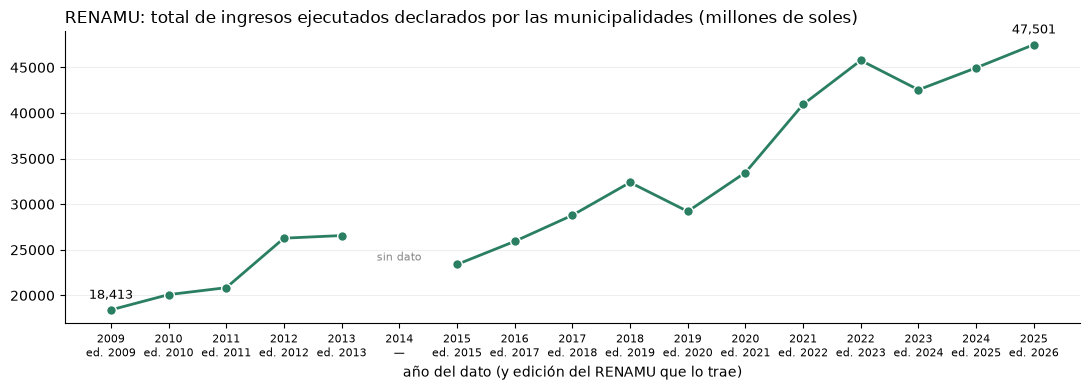

In [7]:
filas = []
for a, e in MAPEO["ediciones"].items():
    if e.get("existe", True) is False:
        continue
    b = e["ingresos"]
    r = csvs[(csvs["anio"] == a) & (csvs["archivo"] == b["archivo"])].iloc[0]
    p = RAIZ / r["ruta"]; fmt = detectar_formato(p)
    reales = {c.upper(): c for c in fmt["columnas"]}
    x = a_pandas(leer_csv(spark, str(p), fmt).select(reales[b["informo"]], reales[b["total"]]))
    informo = x[reales[b["informo"]]].astype("string").str.strip() == "1"
    total = a_numero(x[reales[b["total"]]])
    filas.append({"edicion": a, "año_del_dato": e["anio_dato"], "archivo": b["archivo"], "municipalidades": len(x),
                  "informaron": int(informo.sum()), "ingreso_total_millones": round(float(total.sum()) / 1e6, 1)})
serie = pd.DataFrame(filas).set_index("edicion")
display(serie)

fig, ax = plt.subplots(figsize=(11, 4))
s = serie.set_index("año_del_dato")["ingreso_total_millones"].reindex(range(serie["año_del_dato"].min(), serie["año_del_dato"].max() + 1))
ax.plot(s.index, s.values, "-o", color="#2a7f62", lw=2, ms=7, markeredgecolor="white")
for x_, y_ in s.dropna().iloc[[0, -1]].items():
    ax.annotate(f"{y_:,.0f}", (x_, y_), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.annotate("sin dato", (2014, s.dropna().loc[2013]), textcoords="offset points", xytext=(0, -18), ha="center", fontsize=8, color="#888")
ax.set_title("RENAMU: total de ingresos ejecutados declarados por las municipalidades (millones de soles)", loc="left")
ed = serie.reset_index().set_index("año_del_dato")["edicion"]
ax.set_xticks(list(s.index), [f"{a}\ned. {ed[a]}" if a in ed.index else f"{a}\n—" for a in s.index])
ax.set_xlabel("año del dato (y edición del RENAMU que lo trae)"); ax.tick_params(axis="x", labelsize=8)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#eee"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Nota del gráfico.** El eje es el **año del dato**, no la edición. 2014 queda vacío porque la edición 2014 no trae el cuadro y la 2015 ya reporta 2015. 2016 sí tiene dato aunque la edición 2016 no tenga el cuadro: desde 2017 cada edición reporta el año anterior, y la edición 2017 trae 2016.

## 7. Para Silver (`05b`)

La tabla `renamu_finanzas` queda con una fila por municipalidad y edición, con códigos tomados de `data/silver/renamu_mapeo.yaml`.

- **Llaves:** `ubigeo`, `edicion`, `anio_dato` y `tipo_municipalidad`.
- **Ingresos:** `ing_informo`, `ing_total`, `ing_corrientes`, `ing_capital`, `ing_transferencias` y `ing_financiamiento`. En 2009, `ing_financiamiento` = `_71` + `_74`.
- **Gastos:** `gas_informo`, `gas_total`, `gas_corrientes`, `gas_capital` y `gas_servicio_deuda`.
- **Trazabilidad:** `_run_id`, `_fecha_proceso_utc`, `_fuente`, `_archivo_origen`, `_sha256_origen` y `_fecha_descarga`.

Una variable que no existe en la edición queda vacía (por ejemplo, la III de ingresos en 2009). Las ediciones 2014 y 2016 no aportan filas, y el año del dato 2014 queda sin información.

In [8]:
spark.stop()